# Error-correcting codes: 선형대수로 이해하는 오류 복구

예제는 위에서부터 차례로 실행하면 된다. Python standard library만 사용하고, 그림 네 개도 notebook에 들어 있다. Coding exercise의 starter와 reference solution은 함수 이름이 달라서 Run All을 실행해도 작성 중인 풀이를 덮어쓰지 않는다.

[Read in English](https://pilkwangkim.github.io/posts/Error-Correcting-Codes-From-Scratch/) · [Python 구현](https://pilkwangkim.github.io/assets/code/error-correcting-codes.py)

송신자가 네 bit로 만들 수 있는 열여섯 **message** 중 하나를 골라, 추가 정보 없이 그대로 보낸다고 하자. 수신자는 `1001`을 받았다. 원래 보낸 값도 `1001`이었을까? 아니면 `1011`을 보냈는데 왼쪽에서 세 번째 bit가 1에서 0으로 바뀐 걸까? 둘 다 가능한 설명이지만, 가능한 원본이 이 두 개뿐인 것은 아니다.

어느 위치에서 몇 bit가 바뀌어도 된다고 하면, 열여섯 message 모두 `1001`로 바뀔 수 있다. 어떤 message를 고르든 같은 길이로 전송한다면, 추가 bit를 붙여도 모든 오류를 복구할 수 있는 것은 아니다. 전송값의 어떤 bit든 바뀔 수 있다면, 원래의 전송값이 다른 message의 전송값과 같아질 수도 있기 때문이다. 따라서 오류 복구를 설계할 때는 **어떤 오류까지 반드시 고칠 것인지**부터 정해야 한다.

가장 간단한 목표로 **오류가 없거나 bit 하나만 뒤집힌 모든 경우에 원래 message를 복구한다**고 정해 보자. 이것이 “최대 한 bit 오류를 고친다”는 뜻이다. 실제 channel에서 두 bit 오류가 절대 생기지 않는다는 뜻도, 수신자가 오류 개수를 알아냈다는 뜻도 아니다. Code가 이 범위의 오류를 모두 고칠 수 있도록 만들고, 실제로 그런지 증명하겠다는 것이다.

그런데 네 bit를 그대로 보내면 이 목표조차 달성할 수 없다. 수신값이 `1001`일 때, 오류가 0개 또는 1개인 경우의 가능한 원본을 **전부** 적으면 다음과 같다. 위치는 왼쪽부터 센다.

| 가능한 원본 | 전송 중 변화 | 받은 값 |
| :---: | :--- | :---: |
| `1001` | 변화 없음 | `1001` |
| `0001` | 1번 bit가 0에서 1로 바뀜 | `1001` |
| `1101` | 2번 bit가 1에서 0으로 바뀜 | `1001` |
| `1011` | 3번 bit가 1에서 0으로 바뀜 | `1001` |
| `1000` | 4번 bit가 0에서 1로 바뀜 | `1001` |


“최대 하나”에는 첫 행처럼 오류가 없는 경우도 포함된다. “정확히 하나”라고 했다면 첫 행을 제외한 네 개가 후보가 된다. 어느 경우든 수신자는 서로 다른 원본에서 똑같은 값을 받는다. 후보 하나를 고르면 다른 전송에서는 틀리므로, **받은 네 bit만으로 원본을 항상 맞히는 방법은 없다.**

이 목표를 이루려면 원래 message 외에도 오류를 판단할 단서를 전송해야 한다. 송신자는 각 message를 더 긴 bit 문자열인 **codeword**로 바꾸어 보낼 수 있다. 열여섯 message는 모두 유지한다. 제한하는 것은 원래 message의 종류가 아니라 실제로 전송할 문자열이다. 수신자도 변환 규칙을 알고 있지만, 이번에 보낸 message가 무엇인지는 모른다.

**유효한 codeword**는 정해 둔 변환 규칙으로 만들 수 있는 문자열을 뜻한다. 받은 값이 유효하다고 해서 실제 원본과 같다는 뜻은 아니다. Codeword가 아닌 값을 받으면 오류가 있다는 사실은 알 수 있지만, 복구까지 하려면 한 가지 조건이 더 필요하다. **서로 다른 codeword에서 오류가 0개 또는 1개 생겼을 때 나올 수 있는 수신값들이 겹치지 않아야 한다.** 이런 codeword를 어떻게 고르고, bit를 얼마나 더 보내야 하는지가 핵심 문제다.

## 1. Bit를 vector로 표현하기: 덧셈은 modulo 2로


Bit가 뒤집힌다는 것은 0이 1로, 또는 1이 0으로 바뀐다는 뜻이다. 이 변화를 계산하려면 message와 codeword를 bit로 이루어진 vector로 나타내면 편리하다. **Bit**의 값은 0 또는 1이며, 덧셈을 다음과 같이 정한다. 보통 덧셈과 달리 $1+1$의 결과가 0이다.

$$
\begin{aligned}
0+0&=0,&\qquad0+1&=1,\\
1+0&=1,&\qquad1+1&=0.
\end{aligned}
\tag{1}
$$

이 덧셈을 **modulo 2** 덧셈 또는 **XOR**라고 하며, $a\oplus b$로도 쓴다. 곱셈은 0과 1의 보통 곱셈과 같다. 두 원소 0, 1에 이 연산을 적용하는 수 체계가 field $\mathbb F_2$다. **Field**는 덧셈과 곱셈의 기본 법칙이 성립하고, 0이 아닌 모든 원소로 나눌 수 있는 수 체계를 말한다. $\mathbb F_2$에서 0이 아닌 원소는 1뿐이고, 그 역수도 1이다.

덧셈만 이 규칙으로 바꾸면 익숙한 vector·matrix 연산을 $\mathbb F_2$에서도 할 수 있다. 예를 들어

$$
\begin{pmatrix}1&1&0\\0&1&1\end{pmatrix}
\begin{pmatrix}1\\1\\0\end{pmatrix}
=\begin{pmatrix}0\\1\end{pmatrix}.
\tag{2}
$$

첫 번째 성분을 구하는 식은 $1\cdot1+1\cdot1+0\cdot0$이다. Modulo 2로 계산하므로 결과는 2가 아니라 0이다. Python에서는 bit 값에 `a ^ b`를 적용하면 XOR을 계산한다. 여러 bit를 모두 XOR한 값은 `sum(values) % 2`로도 구할 수 있다.

송신한 codeword를 $c$, 수신한 vector를 $r$, 오류 위치를 표시하는 **error vector**를 $e$라고 하자. $e$의 $i$번째 성분은 수신한 $i$번 bit가 보낸 bit와 다를 때 1이고, 같으면 0이다. 그러면

$$
r=c+e,\qquad c=r+e.
\tag{3}
$$

$1+1=0$이므로 덧셈과 뺄셈이 같다. 오류 위치만 알면 해당 bit를 한 번 더 뒤집어서 원래 값으로 돌릴 수 있다. 어려운 것은 이 연산이 아니라, **어느 위치의 값이 달라졌는지, 즉 $e$가 무엇인지 알아내는 일**이다. 여기서 오류 개수는 최종 수신값에서 원본과 다른 위치의 개수다. Interactive 예시에서 bit를 누른 횟수와는 다르다. 같은 bit를 두 번 뒤집으면 원래 값으로 돌아오므로 그 위치는 오류에 포함되지 않는다.

**Block code**는 $k$ bit message를 $n$ bit codeword로 바꾼다. 서로 다른 message는 서로 다른 codeword로 바뀌어야 한다. 그렇지 않으면 오류가 전혀 없어도 원래 message를 구별할 수 없다. **Rate** $R=k/n$은 원래 message 길이를 전송하는 codeword 길이로 나눈 값이다. 추가한 길이 $n-k$가 **redundancy**다. 이 비율을 정의할 때 원래 message bit가 codeword의 특정 위치에 그대로 남아 있어야 하는 것은 아니다. 다만 아래 예제들은 원래 bit를 그대로 읽을 수 있는 형태를 사용한다. 여기서 가정하는 channel에서는 bit 값만 바뀐다. Bit가 삽입되거나 삭제되거나 순서가 뒤바뀌는 오류는 다른 방식으로 다뤄야 한다. [MIT 6.02](https://web.mit.edu/6.02/www/f2011/handouts/6.pdf)

송신자의 **encoder**는 message를 codeword로 바꾼다. 수신자의 **decoder**는 오류가 섞였을 수 있는 수신값에서 원래 message를 찾는다. 양쪽은 어떤 code를 쓸지, bit를 어떤 순서로 배치할지 미리 알고 있다. 다만 수신자는 실제로 어떤 message를 보냈는지 모른다. 길이 $n$의 bit 문자열을 **word**라고 하며, 그중 code의 조건을 만족하는 것만 codeword다.

## 2. Repetition code: 같은 bit를 여러 번 보내기


먼저 message bit 하나만 보호해 보자. 0 또는 1을 그대로 한 번 보내면, 수신자는 오류 없이 도착한 1과 0이 뒤집혀서 생긴 1을 구별할 수 없다. 한 bit 오류까지 복구하려고 같은 값을 세 번 보내는 **repetition code**를 사용해 보자. 가능한 codeword는 두 개다.

$$
0\longmapsto000,\qquad 1\longmapsto111.
\tag{4}
$$

수신자는 **majority vote**, 즉 더 많이 받은 값을 고르는 방식으로 원래 bit를 결정한다. `000`이 `010`으로 바뀌어도 0이 두 개이므로 원래 값 0을 복구한다. 뒤집힌 위치가 어디든 마찬가지다. 하지만 `000`이 `110`으로 바뀌면 1을 고르므로 원래 값을 복구하지 못한다.

**실제로 오류가 없거나 한 bit만 뒤집혔다면**, 적어도 두 bit는 보낸 값을 유지한다. 따라서 더 많이 받은 값을 고르면 반드시 맞는다. 이것으로 처음 정한 한 bit 오류 복구 목표를 만족한다는 것을 증명했다. Decoder가 먼저 오류 개수를 알아내는 것은 아니다. 받은 값에 그대로 majority vote를 적용하며, 두 bit나 세 bit가 뒤집히면 반드시 반대 값을 고른다. 다만 rate는 $1/3$에 불과하다. 네 bit message를 각각 이 방식으로 보호하려면 열두 bit를 보내야 한다.

어떤 오류를 반드시 고치는지와, 실제로 얼마나 자주 틀리는지는 서로 다른 질문이다. 실패 확률까지 구하려면 오류가 생기는 방식을 확률로 정해야 한다. **Binary symmetric channel**, 줄여서 **BSC**는 각 bit가 같은 확률 $p$로, 서로 독립적으로 뒤집히는 model이다. 세 bit를 보내면 오류가 0개, 1개, 2개, 3개인 경우가 모두 생길 수 있다. Code와 decoder는 바꾸지 않는다. 같은 majority vote가 오류 0개·1개에서는 맞고, 2개·3개에서는 틀린다는 결과를 이용한다. 따라서 이 decoder가 틀릴 확률은 두 bit 또는 세 bit가 뒤집힐 확률을 더하면 된다.

$$
\begin{aligned}
P_{\mathrm{fail},3}
&=\binom32p^2(1-p)+p^3\\
&=3p^2-2p^3.
\end{aligned}
\tag{5}
$$

첫 항은 두 bit가 뒤집히는 경우다. 뒤집히지 않은 bit의 위치를 고르는 방법이 세 가지이므로 3을 곱한다. 두 번째 항은 세 bit가 모두 뒤집히는 경우다. $p=0.1$이면 decoder가 원래 bit를 잘못 판단할 확률은 $0.028$로, 보호 없이 보낼 때의 $0.1$보다 작다. 이 값은 **전송 블록에 오류가 하나라도 생길 확률**과는 다르다. 예를 들어 `000`이 `010`으로 바뀌었다면 전송 오류는 생겼지만, majority vote는 원래 message bit인 0을 정확히 반환한다. 식 (5)는 이렇게 고칠 수 있는 오류까지 모두 세는 것이 아니라, decoder가 틀린 값을 반환하는 경우의 확률이다. [IBM의 classical repetition code 설명](https://quantum.cloud.ibm.com/learning/en/courses/foundations-of-quantum-error-correction/correcting-quantum-errors/repetition-codes)



**Majority vote는 왜 p가 1/2보다 작을 때 오류 확률을 줄일까?**


Majority vote가 틀릴 확률에서, 보호 없이 보냈을 때의 오류 확률을 빼 보자.

$$
P_{\mathrm{fail},3}-p
=p(1-p)(2p-1).
\tag{6}
$$

$0<p<1/2$에서는 이 차이가 음수이므로 majority vote를 쓰는 편이 낫다. $p=0,1/2,1$에서는 차이가 없고, $1/2<p<1$에서는 오히려 오류 확률이 커진다. 다만 이는 받은 값에 그대로 majority vote를 적용했을 때의 결과다. BSC에서 $p>1/2$라는 사실을 알고 있다면, 받은 bit를 전부 뒤집은 뒤 처리할 수 있다. 이렇게 하면 오류 확률이 $1-p$인 channel과 같아진다.

홀수 $n$에 대해서도, 과반수의 bit가 뒤집히는 모든 경우의 확률을 더하면 된다.

$$
P_{\mathrm{fail},n}
=\sum_{j=(n+1)/2}^{n}
\binom nj p^j(1-p)^{n-j}.
\tag{7}
$$

**Binomial coefficient** $\binom nj$는 $n$개 위치 중 뒤집힐 $j$개를 고르는 경우의 수다. 각 bit의 오류가 서로 독립이므로 한 error pattern의 확률을 $p^j(1-p)^{n-j}$로 계산할 수 있다. 반면 **burst error**는 짧은 연속 구간에 오류가 몰리는 경우다. 이런 오류에는 독립적인 flip을 가정한 식을 그대로 적용할 수 없다. 모든 복사본이 함께 뒤집히면 majority vote로도 고칠 수 없다.



Python 예제는 standard library만 사용한다. 앞서 정의한 encoder와 check 함수를 뒤에서도 사용하므로 위에서부터 차례로 실행하면 된다. 다운로드용 모듈은 진단 결과를 더 자세히 반환하도록 따로 구현했다. 따라서 본문의 함수와 API가 완전히 같지는 않다.


In [1]:
from math import comb

def repetition_failure(n, p):
    """Exact information-bit error probability for odd n on a BSC."""
    if n < 1 or n % 2 == 0 or not 0 <= p <= 1:
        raise ValueError("Use a positive odd n and 0 <= p <= 1")
    # Sum the probabilities of all patterns with a wrong majority.
    return sum(comb(n, j) * p**j * (1 - p)**(n - j)
               for j in range(n // 2 + 1, n + 1))

assert abs(repetition_failure(3, 0.1) - 0.028) < 1e-12


먼저 받은 bit 하나를 직접 뒤집어 보고, 다음에는 두 개를 뒤집어 보자. 반복 횟수를 바꾸면서 BSC에서 decoder가 틀릴 확률과 rate도 비교해 보자. Bit를 직접 누르면 특정 error pattern 하나를 확인할 수 있다. 그래프는 이렇게 고른 pattern의 결과가 아니라, BSC에서 발생할 수 있는 모든 pattern을 확률에 따라 합산한 결과다.


[Interactive example 열기](https://pilkwangkim.github.io/posts/Error-Correcting-Codes-From-Scratch-KR/#lab-ecc-repetition)


## 3. Parity bit 하나로 오류를 발견할 수는 있지만, 위치는 모른다

네 bit message로 돌아오면, 각 bit를 세 번씩 반복할 때 열두 bit를 보내야 한다. 추가 bit를 하나만 보내면 무엇까지 할 수 있을까? Message bit를 XOR한 값 하나를 뒤에 붙이면, 모든 codeword에서 1의 개수가 짝수가 된다. 이 조건을 **even parity**라고 한다. 여기서는 목표도 달라진다. 오류를 고치는 대신 오류가 있다는 사실을 알아내는 방법이며, 아직 같은 복구 목표를 더 적은 bit로 달성한 것은 아니다.

Message가 `1011`이면 $1\oplus0\oplus1\oplus1=1$을 붙여 `10111`을 보낸다. 수신자는 받은 다섯 bit를 모두 XOR한다. 결과가 1이면 받은 값이 정상적인 codeword가 아니라는 뜻이다.

네 bit message를 다섯 bit로 보내므로 rate는 $4/5$다. 각 bit를 따로 반복하지 않고, message 전체를 check bit 하나로 검사하는 셈이다. 추가로 보내는 bit는 줄었지만, 이 check로 알 수 있는 것도 줄었다. Even parity를 만족하는지는 알 수 있어도 어느 bit를 고쳐야 하는지는 알 수 없다.

전송하는 다섯 bit를 모두 XOR하면 0이다. Bit 하나가 뒤집힐 때마다 이 XOR 결과도 바뀐다. 따라서 뒤집힌 bit 수가 홀수이면 1, 짝수이면 0이다. Parity bit 하나로 **홀수 개 bit가 뒤집힌 오류는 모두 찾지만, 두 개·네 개처럼 짝수 개가 뒤집힌 오류는 모두 놓친다.** 오류 위치도 알 수 없다. [University of Michigan EECS 373](https://www.eecs.umich.edu/courses/eecs373.w05/lecture/errorcode.html)

예를 들어 message `1011`을 encoding한 `10111`에서 2번과 4번 bit가 뒤집히면 `11101`이 된다. 한편 message `1110`을 encoding한 값도 `11101`이다. 이 값을 오류 없이 받은 경우와 앞의 두 bit 오류가 생긴 경우를 비교하면, 수신값이 똑같다. 둘 다 even parity를 만족하므로, 오류가 최대 두 개까지 날 수 있다면 이 parity check로는 두 경우를 구별할 수 없다.

오류가 하나뿐이라고 해도 이 check만으로는 위치를 찾지 못한다. 다섯 bit 중 어느 것이 뒤집혀도 결과가 똑같이 1이기 때문이다. 오류 위치를 구별하려면 check가 여러 개 있어야 하고, **뒤집힌 위치마다 check 결과의 조합이 달라야 한다.**

Parity bit를 뒤집어 본 다음, message bit 두 개를 뒤집어 보자. 시뮬레이션에서는 어떤 값을 보냈고 어디에 오류를 넣었는지 알 수 있다. 하지만 실제 수신자에게 있는 것은 받은 값과 check 결과뿐이다.


[Interactive example 열기](https://pilkwangkim.github.io/posts/Error-Correcting-Codes-From-Scratch-KR/#lab-ecc-parity)


## 4. 오류 검출과 복구의 한계는 Hamming distance로 정해진다

Repetition과 parity는 왜 서로 다른 오류에 실패할까? 한 codeword가 다른 codeword로 바뀌려면 몇 bit가 뒤집혀야 하는지 세어 보면 두 방법을 같은 기준으로 비교할 수 있다.

**Hamming distance** $d_H(u,v)$는 길이가 같은 두 bit 문자열에서 값이 다른 위치의 개수다. **Weight** $w(u)$는 $u$에 들어 있는 1의 개수다. 두 문자열을 XOR하면 값이 다른 위치에만 1이 남으므로

$$
d_H(u,v)=w(u+v).
\tag{8}
$$

예를 들어 `1001`과 `1011`은 3번 bit만 다르므로 거리가 1이다. `000`과 `111`의 거리는 3이다. 여기서 거리는 한 문자열을 다른 문자열로 바꾸는 데 필요한 **최소 bit 변경 횟수**다. 그림에서 자로 잰 선의 길이가 아니다.

가능한 codeword를 모은 집합을 **codebook** $C$라고 하자. Codeword가 두 개 이상일 때 **minimum distance**를 다음과 같이 정의한다.

$$
d_{\min}=\min_{u\ne v,\ u,v\in C}d_H(u,v).
\tag{9}
$$

오류가 생기면 받은 값은 전송한 codeword와 달라진다. 이를 다른 message의 codeword와 혼동하지 않으려면 codeword 사이의 거리가 충분히 커야 한다. 이 거리가 block code로 오류를 어디까지 찾고 고칠 수 있는지 결정한다. 이제 검출이나 복구를 보장하려는 최대 오류 수를 0 이상의 정수 $t$로 나타내자. 한 bit 오류 복구 목표라면 $t=1$이고, $t$가 커지면 더 많은 오류를 처리하도록 요구하는 것이다. $t$는 받은 값에서 알아낸 오류 개수가 아니라 **설계할 때 정하는 보장 범위**다. [Hamming, 1950](https://doi.org/10.1002/j.1538-7305.1950.tb00463.x) [MIT 6.02](https://web.mit.edu/6.02/www/f2011/handouts/6.pdf)

### 최대 t개의 오류를 모두 검출하려면 minimum distance가 t + 1 이상이어야 한다

수신자는 $r$이 codebook $C$에 들어 있는지 검사한다. $1\le w(e)\le t<d_{\min}$이라면, 오류가 섞인 값이 다른 codeword와 같아질 수는 없다. 만약 같아진다면 두 codeword 사이의 거리가 $d_{\min}$보다 작다는 뜻이 되어 minimum distance의 정의에 어긋난다. 따라서 이 범위의 오류는 모두 찾아낼 수 있다.

반대로 $d_{\min}\le t$라고 하자. 가장 가까운 두 codeword를 고르고, 서로 다른 위치를 모두 뒤집으면 한쪽이 다른 쪽으로 바뀐다. 필요한 flip은 $t$번 이하다. 받은 값이 다른 정상적인 codeword이므로, codeword인지 검사하는 것만으로는 오류를 알 수 없다. 따라서

$$
\begin{gathered}
\text{detect up to }t\text{ flips}\\
\Longleftrightarrow\quad d_{\min}\ge t+1.
\end{gathered}
\tag{10}
$$

### 최대 t개의 오류를 모두 복구하려면 minimum distance가 2t + 1 이상이어야 한다

오류를 찾는 것만으로는 복구할 수 없다. 원래 어떤 codeword를 보냈는지까지 알아내야 한다. 한 codeword에서 거리가 $t$ 이하인 모든 word를 모은 집합을 반지름 $t$의 **Hamming ball**이라고 하자.

서로 다른 두 codeword $u,v$에서 모두 거리가 $t$ 이하인 수신값 $r$이 있다고 가정해 보자. Triangle inequality에 따라

$$
\begin{aligned}
d_H(u,v)&\le d_H(u,r)+d_H(r,v)\\
&\le2t.
\end{aligned}
\tag{11}
$$

$d_{\min}>2t$라면 이 부등식은 성립할 수 없다. 따라서 서로 다른 codeword를 중심으로 한 ball은 겹치지 않는다. 실제 오류가 최대 $t$개라면, 보낸 codeword는 수신값에서 거리가 $t$ 이하이므로 반드시 후보에 들어간다. Ball이 겹치지 않으므로 같은 조건을 만족하는 다른 codeword는 없다. 즉, 후보가 하나는 존재하고 둘 이상일 수는 없다. 수신자는 이 유일한 codeword를 고르면 된다.

반대로 두 codeword가 $d\le2t$개 위치에서 다르다고 하자. 두 codeword의 bit가 같은 위치는 그대로 두고, 다른 위치 중 대략 절반은 한쪽 codeword에서, 나머지는 다른 쪽에서 골라 $r$을 만들 수 있다. $r$에서 두 codeword까지의 거리는 각각 $\lfloor d/2\rfloor$와 $\lceil d/2\rceil$이며, 둘 다 $t$ 이하다. 두 기호는 각각 정수로 내림과 올림을 뜻한다. 예를 들어 $d=3$이면 두 거리는 1과 2다. 두 codeword 모두 최대 $t$번의 flip으로 $r$이 될 수 있으므로, 어떤 decoder를 쓰더라도 항상 둘을 구분할 수는 없다. 따라서

$$
\begin{gathered}
\text{correct up to }t\text{ flips}\\
\Longleftrightarrow\quad d_{\min}\ge2t+1.
\end{gathered}
\tag{12}
$$

식 (12)는 **이 범위의 오류를 모두 고칠 수 있는 decoder를 만들 수 있다**는 뜻이다. 어떤 decoding 알고리즘을 써도 된다는 뜻은 아니다. 한 가지 방법은 받은 값에서 거리가 $t$ 이하인 유일한 codeword를 반환하고, 그런 codeword가 없으면 복구 실패를 알리는 것이다.

앞의 두 code를 비교해 보자. 세 bit repetition code는 $d_{\min}=3$이다. `000`과 `111`이 세 위치에서 다르므로 한 bit가 뒤집혀도 원래 어느 codeword였는지 구별할 수 있다. 반면 parity bit 하나를 붙인 code는 $d_{\min}=2$다. 한 bit만 뒤집히면 오류를 찾지만, 어느 위치를 고쳐야 하는지는 알 수 없다. 서로 다른 두 bit를 뒤집으면 다른 정상적인 codeword가 된다.


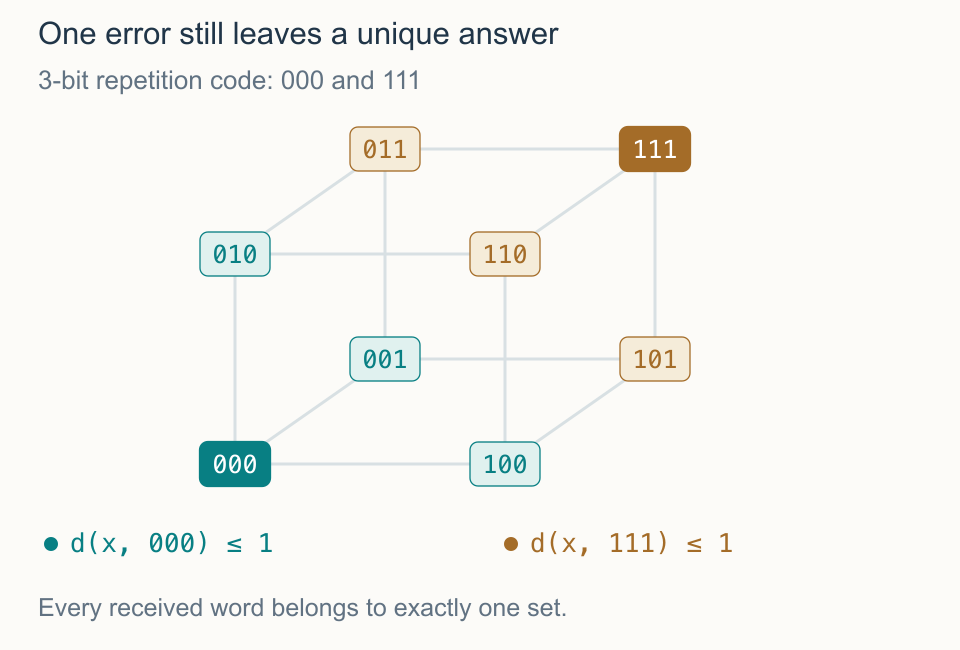

*그림 1. Edge 하나를 따라가면 bit 하나가 바뀐다. `000`에서 거리가 1 이하인 word와 `111`에서 거리가 1 이하인 word는 서로 겹치지 않는다. 하지만 두 bit까지 뒤집힐 수 있다면, 일부 수신값은 두 codeword 중 어느 쪽에서도 나올 수 있다.*


Repetition codeword는 `000`과 `111`로 고정하고, 받은 word를 `001`로 정해 보자. 한 bit 오류까지 고치려는 목표에서는 거리 1 이내의 후보가 `000`뿐이다. 같은 code로 두 bit 오류까지 고치려고 하면 `111`도 후보가 된다. 1번과 2번 bit가 뒤집히면 `001`이 되기 때문이다. 이 code는 첫 번째 목표는 달성하지만 두 번째 목표는 달성할 수 없다. Interactive 예시에서 $t$를 바꾸며, 복구하려는 오류 범위를 넓힐 때 원본 후보가 어떻게 달라지는지 확인해 보자.


[Interactive example 열기](https://pilkwangkim.github.io/posts/Error-Correcting-Codes-From-Scratch-KR/#lab-ecc-distance)




**Bit 문자열에서도 triangle inequality가 성립하는 이유**


$u$와 $v$의 값이 다른 위치에서는 $r$이 두 값과 동시에 같을 수 없다. 따라서 그 위치는 $d_H(u,r)+d_H(r,v)$에서 적어도 한 번은 센다. 이를 모든 위치에 대해 더하면 식 (11)을 얻는다. Euclidean geometry나 제곱근 없이도 bit가 다른 위치를 세는 것만으로 증명할 수 있다.



## 5. 한 bit 오류를 찾으려면 check bit가 몇 개 필요할까?


네 bit message에서 한 bit 오류까지 복구한다는 원래 목표로 돌아오자. Repetition은 열두 bit로 이 목표를 달성한다. Parity bit 하나를 붙이면 다섯 bit만 보내면 되지만, 오류 위치는 찾지 못한다. 여러 check를 message 전체에 걸쳐 사용하면, 각 bit를 세 번씩 반복하지 않고도 오류 위치를 찾을 수 있을까?

Check bit까지 합쳐 한 블록이 $n$ bit라고 하자. 정상적인 codeword는 모두 check를 통과하도록 만든다. 그리고 check 결과만으로 오류가 없는 경우 하나와, $n$개 위치 각각에서 bit 하나가 뒤집힌 경우를 구분하려 한다. 이렇게 구분할 경우가 총 $n+1$가지다. 이는 message의 가짓수가 아니라 **오류가 없는 경우와 오류 위치의 가짓수**다. 어떤 message를 보냈든 같은 방식으로 구별할 수 있어야 한다.

Binary check가 $a$개이면 결과 패턴은 최대 $2^a$개다. 따라서

$$
2^a\ge n+1.
\tag{13}
$$

Check bit도 같은 channel을 지나므로 뒤집힐 수 있다. 따라서 check bit에 생긴 오류도 복구 대상에 포함해야 한다.

Message bit가 네 개이고 check bit가 $a$개라면 전체 길이는 $n=4+a$다. Check bit가 두 개면 블록은 여섯 bit다. 구분할 경우는 일곱 가지인데 check 결과는 네 가지뿐이므로 부족하다. 적어도 check bit가 세 개는 있어야 한다.

Message bit 네 개에 check bit 세 개를 붙이면 $n=7$이고 $2^3=8=n+1$이다. 구분해야 할 경우의 수와 가능한 check 결과의 수가 정확히 맞는다. 이제 각 위치의 오류가 서로 다른 결과를 내도록 check를 설계해야 한다.

Check를 어떻게 만들지 정하지 않아도 codeword 수만으로 같은 한계를 구할 수 있다. Codeword가 $M$개라면, 각 codeword를 중심으로 반지름 1인 ball을 그린다. Ball 하나에는 중심 codeword와 한 bit만 다른 word들을 합쳐 $1+n$개의 word가 들어 있다. 이 ball들이 겹치지 않으면서 가능한 수신값 $2^n$개 안에 모두 들어가야 하므로

$$
M(1+n)\le2^n.
\tag{14}
$$

네 bit로 만들 수 있는 모든 message를 표현하려면 $M=2^4=16$이다. $n=6$이면 message 하나당 오류가 없는 수신값 하나와 한 bit 오류가 난 수신값 여섯 개를 구별해야 한다. 열여섯 message를 모두 구별하려면 이 $16\cdot7=112$개 수신값이 서로 달라야 하지만, 여섯 bit로 만들 수 있는 값은 64개뿐이다. 반드시 겹치는 경우가 생기므로 모든 single-bit 오류를 고칠 수는 없다. $n=7$에서는 $16\cdot8=128=2^7$이다. Hamming code는 이 한계를 달성한다. [Hamming, 1950](https://doi.org/10.1002/j.1538-7305.1950.tb00463.x)



**일반적인 Hamming bound와 erasure의 차이**


반지름 $t$인 ball에는 $\sum_{j=0}^t\binom nj$개의 word가 들어 있다. Weight가 $j$인 error vector는 $n$개 위치 중 뒤집힐 $j$개를 고르면 정해진다. 따라서 원래 codeword를 하나로 정해 복구하려면

$$
M\sum_{j=0}^{t}\binom nj\le2^n.
\tag{15}
$$

이 식은 **necessary condition**이다. 반드시 만족해야 하지만, 식을 만족한다는 이유만으로 그 크기의 code를 항상 만들 수 있는 것은 아니다.

**Erasure**는 flip과 다르다. `01?0`처럼 수신자가 **어느 위치의 값을 모르는지**는 아는 경우다. 값을 모르는 위치가 최대 $v<d_{\min}$개라면 서로 다른 두 codeword가 나머지 위치에서 모두 같을 수 없다. 같다면 둘은 최대 $v$개 위치에서만 다르다는 뜻이므로 minimum distance의 정의에 어긋난다. 따라서 erasure는 최대 $d_{\min}-1$개까지 원래 값을 복구할 수 있다. 잘못된 위치를 모르는 flip을 고치려면 codeword 사이의 거리가 그보다 더 커야 한다. 두 오류가 섞여 있어도 $2t+v<d_{\min}$이면 flip은 최대 $t$개, erasure는 최대 $v$개까지 함께 복구할 수 있다.



## 6. 위치 번호의 binary 표현으로 check 만들기


세 check의 결과를 위치 번호의 binary 표현과 같게 만들면, 그 결과에서 뒤집힌 위치를 바로 읽을 수 있다. 0은 오류가 없는 경우에 쓰고, 1부터 7까지를 일곱 위치의 오류에 대응시키는 것이다. 각 bit의 위치에 1부터 7까지 번호를 붙이자. Check bit는 1, 2, 4번에, message bit 네 개는 나머지 위치에 놓는다.

$$
c=(p_1,p_2,d_1,p_4,d_2,d_3,d_4)^T.
\tag{16}
$$

위 첨자 $T$는 transpose를 뜻한다. 식에서는 가로로 나열했지만 실제로는 column vector다. $p_4$의 4는 네 번째 check bit가 아니라 **4번 위치의 check bit**를 뜻한다.

위치 번호를 binary로 썼을 때 1의 자리가 1인 위치들을 첫 번째 check에 넣는다. 두 번째 check는 2의 자리, 세 번째 check는 4의 자리가 1인 위치들을 사용한다. 세 check의 결과를 각각 $s_1,s_2,s_4$라고 쓰자. 아래 첨자는 첫 번째·두 번째·네 번째 check라는 뜻이 아니라, binary의 자릿값 1·2·4를 뜻한다. 전송할 codeword에서는 세 check의 결과가 모두 0이 되도록 한다.

| Check | 검사할 위치 | XOR 결과 |
| :--- | :--- | :---: |
| $s_1$ | 1, 3, 5, 7 | 0 |
| $s_2$ | 2, 3, 6, 7 | 0 |
| $s_4$ | 4, 5, 6, 7 | 0 |


5를 binary로 쓰면 `101`이므로 5번 bit는 check 1과 4에 들어가고 check 2에는 들어가지 않는다. 3번 bit는 check 1과 2에 들어간다. 이렇게 하면 어느 위치든 적어도 하나의 check에 들어가며, 위치마다 check의 조합도 달라진다. 앞서 요구한 조건을 만족하는 것이다.

1, 2, 4를 binary로 쓰면 각각 `001`, `010`, `100`이다. 따라서 이 세 위치는 각각 check 하나에만 들어간다. 여기에 parity bit를 놓으면 다른 두 check의 결과를 바꾸지 않으면서, 해당 check의 XOR 결과가 0이 되도록 값을 정할 수 있다.

예를 들어 첫 check의 조건은 $p_1+d_1+d_2+d_4=0$이다. Message bit에 해당하는 항을 반대편으로 옮겨도 modulo 2에서는 덧셈과 뺄셈이 같으므로 부호를 바꿀 필요가 없다. 같은 방식으로 parity bit를 각각 구하면

$$
\begin{aligned}
p_1&=d_1+d_2+d_4,\\
p_2&=d_1+d_3+d_4,\\
p_4&=d_2+d_3+d_4.
\end{aligned}
\tag{17}
$$

덧셈은 모두 modulo 2다. 3, 5, 6, 7번 위치에 넣을 네 message bit는 자유롭게 고를 수 있다. 이 네 값이 정해지면 나머지 세 parity bit는 식 (17)에 따라 정해진다. 세 parity bit를 따로 골라서 새로운 message 정보를 더 넣는 것은 아니다.

Message가 $m=(1,0,1,1)^T$이면 $p_1=0$, $p_2=1$, $p_4=0$이므로 codeword는 `0110011`이다. 이처럼 정해진 위치에서 원래 message bit를 그대로 읽을 수 있는 code를 **systematic code**라고 한다. Message bit를 한곳에 모을 필요는 없다. Check bit와 사이사이에 섞여 있어도 원래 값이 그대로 들어 있으면 된다. 위치 번호로 check를 정하는 이 방법이 표준적인 Hamming construction이다. [MIT 6.02, §6.4](https://web.mit.edu/6.02/www/f2011/handouts/6.pdf)


In [2]:
def as_bits(values, length):
    """Validate a bit sequence; strings such as '1011' are accepted."""
    values = tuple(values)
    if len(values) != length or any(
        not ((type(x) is int and x in (0, 1))
             or (type(x) is str and x in ("0", "1"))) for x in values
    ):
        raise ValueError(f"Expected {length} bits")
    return tuple(int(x) for x in values)

def encode_hamming(message):
    d1, d2, d3, d4 = as_bits(message, 4)
    # Each parity bit makes one overlapping check sum to zero.
    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4
    return (p1, p2, d1, p4, d2, d3, d4)

assert encode_hamming("1011") == (0, 1, 1, 0, 0, 1, 1)


## 7. Parity-check matrix로 검사 조건 묶기


앞의 세 check 식을 matrix 방정식 하나로 쓸 수 있다. 새로운 encoding 규칙이 생기는 것이 아니라, 같은 조건을 다른 형태로 표현하는 것이다.

$$
\begin{gathered}
H=\begin{pmatrix}
1&0&1&0&1&0&1\\
0&1&1&0&0&1&1\\
0&0&0&1&1&1&1
\end{pmatrix},\\
Hc=0.
\end{gathered}
\tag{18}
$$

$H$를 **parity-check matrix**라고 한다. $i$행 $j$열이 1이면 $i$번째 check에 $j$번 bit가 들어간다는 뜻이다. $H$를 곱하면 각 행에서 지정한 bit들을 XOR한다. **행을 보면 어떤 bit를 함께 검사하는지, 열을 보면 그 위치의 오류가 어떤 check에 영향을 주는지 알 수 있다.**

이 code에서는 세 check를 모두 통과하는 일곱 bit 문자열을 codeword로 정한다. 이 조건이 바로 $Hc=0$이므로, codeword를 모두 모은 집합은 $H$의 **kernel**, 또는 **null space**다.

$$
\begin{aligned}
C&=\ker H\\
&=\lbrace c\in\mathbb F_2^7:Hc=0\rbrace.
\end{aligned}
\tag{19}
$$

여기서 $\mathbb F_2^7$은 가능한 모든 일곱 bit column vector의 집합이다. Kernel은 matrix를 곱했을 때 zero vector가 되는 모든 입력을 말한다. Matrix 곱셈은 linear map이므로 두 codeword를 더해도 codeword다. $H(u+v)=Hu+Hv=0$이기 때문이다. 이처럼 vector space를 이루는 codebook을 **linear code**라고 한다. [MIT MAS 160/510 강의 자료](https://courses.media.mit.edu/2007fall/mas160/error.pdf)

$H$의 1, 2, 4번 열을 모으면 $3\times3$ identity matrix다. 따라서 세 행은 linearly independent하고 $\operatorname{rank}H=3$이다. Rank–nullity 관계를 적용하면

$$
\begin{gathered}
\dim C=7-3=4,\\
|C|=2^4=16.
\end{gathered}
\tag{20}
$$

$\lvert C\rvert$는 $C$에 들어 있는 codeword의 개수다. 자유롭게 정할 수 있는 binary 좌표가 네 개이고, 각 좌표의 값은 0 또는 1이다. 따라서 가능한 vector는 열여섯 개다. Dimension이 4라고 해도, 실수에서처럼 vector가 무한히 많은 것은 아니다.

Encoder도 linear map으로 쓸 수 있다. 네 message bit를 column vector $m=(d_1,d_2,d_3,d_4)^T$로 나타내자. Message를 **column vector**로 놓았으므로, 이를 일곱 bit codeword로 바꾸는 **generator matrix**의 크기는 $7\times4$다.

$$
\begin{gathered}
G=\begin{pmatrix}
1&1&0&1\\
1&0&1&1\\
1&0&0&0\\
0&1&1&1\\
0&1&0&0\\
0&0&1&0\\
0&0&0&1
\end{pmatrix},\\
c=Gm.
\end{gathered}
\tag{21}
$$

$G$의 각 열은 standard basis인 message `1000`, `0100`, `0010`, `0001`을 각각 encoding한 결과다. 각 행은 식 (17)의 parity 식을 계산하거나 message bit를 그대로 복사한다. Matrix 크기를 보면 역할도 분명하다. $7\times4$인 $G$는 네 좌표를 일곱 좌표로 바꾸고, $3\times7$인 $H$는 그렇게 만든 일곱 좌표를 검사한다.

Message가 `1011`이면 $m$의 첫 번째·세 번째·네 번째 성분이 1이다. 따라서 $Gm$은 $G$의 해당 세 열을 XOR한 값이다. 결과는 앞의 `encode_hamming` 함수와 같은 `0110011`이다. Matrix 곱셈과 Python 함수가 같은 encoding을 계산한다는 것을 확인할 수 있다.



**G와 H가 정확히 같은 열여섯 codeword를 나타내는 이유**


각 check 식에 따라 $HG=0$이므로 $G$로 만든 모든 vector는 $\ker H$에 들어간다. $G$의 3, 5, 6, 7번 행을 모으면 identity matrix다. 따라서 서로 다른 message는 서로 다른 codeword로 바뀌며, $G$의 rank는 4다. $G$의 image는 $H$의 4차원 kernel에 포함된 4차원 subspace이므로 두 공간은 같다.

Message를 row vector로 놓는 교재도 있다. 그 경우에는 앞의 $G$를 transpose한 $4\times7$ generator matrix를 쓰고, $c=mG$로 표현한다. 둘 다 같은 encoding이다. 다만 하나의 계산 안에서는 row vector와 column vector를 사용하는 규칙을 섞으면 안 된다.



## 8. Syndrome으로 오류 위치를 찾는다

수신자는 원래 codeword $c$를 모르므로, 받은 값 $r$에 $H$를 곱한다. 이 결과를 **syndrome** $s$라고 한다.

$$
\begin{aligned}
s&=Hr\\
 &=H(c+e)\\
 &=Hc+He=He.
\end{aligned}
\tag{22}
$$

$Hc=0$이므로 원래 codeword에 해당하는 항은 계산에서 사라진다. 어떤 codeword를 보냈든 이 조건은 같으므로, syndrome은 error vector에 의해서만 정해진다. 그렇다고 세 bit짜리 syndrome으로 일곱 성분의 error vector를 아무 조건 없이 알아낼 수 있는 것은 아니다. 서로 다른 error vector가 같은 syndrome을 만들 수도 있다.

**한 bit 오류 복구 목표를 증명하려면** $e$의 여덟 가지 경우를 확인하면 된다. 오류가 없는 zero vector 하나와, 성분 하나만 1인 일곱 vector다. 다른 오류도 생길 수 있지만, 지금 복구를 보장하려는 범위에는 포함되지 않는다. 세 방정식으로 미지수 일곱 개를 자유롭게 푸는 것이 아니라, 이 여덟 경우가 서로 다른 세 bit짜리 결과를 내는지 확인하는 문제다.

$j$번 bit만 뒤집혔다면 $e$의 $j$번째 성분만 1이고 나머지는 0이다. 이 single-error vector를 $e_j$라고 쓰자. 예를 들어 $e_5=(0,0,0,0,1,0,0)^T$다. $e_j$에 $H$를 곱하면 $H$의 $j$번째 열만 남는다.

$$
s=h_j,
\tag{23}
$$

$h_j$는 $H$의 $j$번째 열이다. 일곱 열은 모두 서로 다르고 zero vector도 없다. 따라서 한 bit 오류 일곱 가지는 각각 다른 syndrome을 만들고, 오류가 없을 때의 zero vector와도 구별된다. **실제로 오류가 없거나 한 bit만 뒤집혔다면** syndrome으로 $e$를 하나로 정할 수 있는 것이다. 그 범위를 벗어나면 같은 syndrome을 만드는 다른 error vector가 있을 수 있다. [MIT MAS 160/510 강의 자료](https://courses.media.mit.edu/2007fall/mas160/error.pdf)


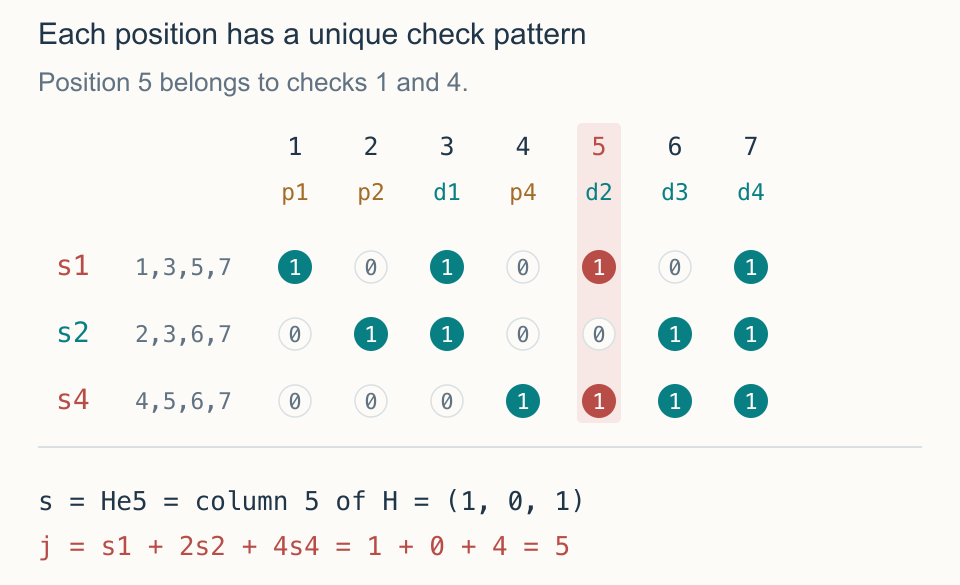

*그림 2. Bit 하나가 뒤집히면 그 bit를 검사하는 check의 결과만 바뀐다. 따라서 5번 bit가 뒤집히면 syndrome은 (1, 0, 1)이다.*


Message `1011`을 codeword `0110011`로 바꾸어 보내고, decoder를 시험하기 위해 5번 bit를 뒤집어 보자. 받은 값은 `0110111`이다. 세 check를 계산하면

$$
\begin{aligned}
s_1&=0+1+1+1=1,\\
s_2&=1+1+1+1=0,\\
s_4&=0+1+1+1=1.
\end{aligned}
\tag{24}
$$

Syndrome의 성분을 $(s_1,s_2,s_4)$ 순서의 tuple로 적으면, 다음 식으로 오류 위치를 구할 수 있다.

$$
j=s_1+2s_2+4s_4.
\tag{25}
$$

결과는 $j=5$다. Tuple의 순서는 보통 binary 수를 적는 순서와 다르다는 점에 주의하자. $j$를 binary로 쓸 때는 높은 자리부터 $s_4s_2s_1$ 순서로 적는다. 예를 들어 syndrome $(1,1,0)$은 3번 위치를 뜻하지만, 3을 binary로 쓰면 `011`이다.

5번 bit를 다시 뒤집으면 `0110011`이 된다. Message bit가 있는 3, 5, 6, 7번 위치를 읽으면 원래 message `1011`을 얻는다.


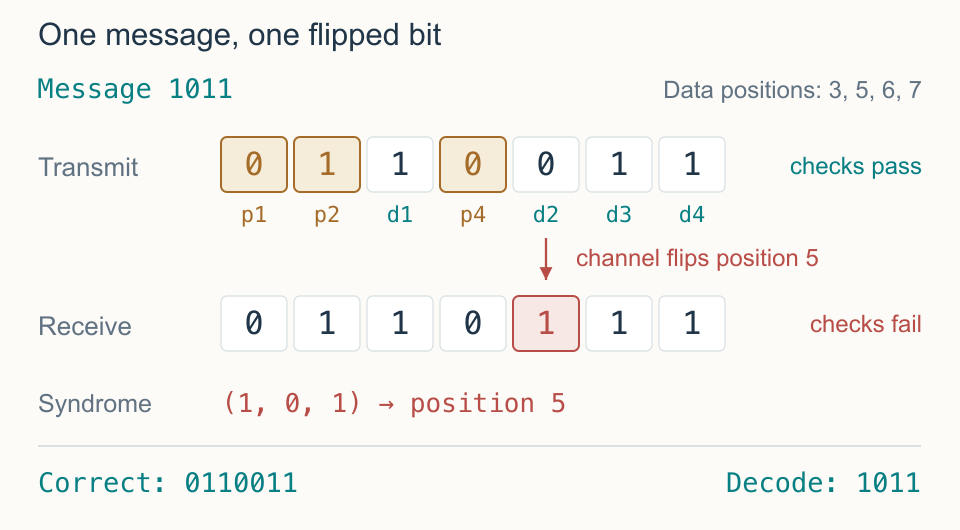

*그림 3. Encoder는 codeword가 세 parity check를 모두 만족하도록 bit를 추가한다. Decoder는 오류가 최대 하나라고 가정하고, check 결과로 뒤집힌 위치를 찾는다. 따로 받은 원본과 비교하는 것이 아니다.*


아래 함수는 어떤 수신값이 들어오든 같은 규칙을 적용한다. 함수 이름 `decode_assuming_one_error`는 복구를 보장하는 조건을 나타낸다. 함수가 실제 오류 개수를 검사했다는 뜻은 아니다. 함수에는 비교할 원본도 전달하지 않는다.


In [3]:
H = (
    (1, 0, 1, 0, 1, 0, 1),
    (0, 1, 1, 0, 0, 1, 1),
    (0, 0, 0, 1, 1, 1, 1),
)

def syndrome(received):
    r = as_bits(received, 7)
    # A dot product over F2: multiply entries, then reduce the sum mod 2.
    return tuple(sum(a * b for a, b in zip(row, r)) % 2 for row in H)

def decode_assuming_one_error(received):
    r = list(as_bits(received, 7))
    s1, s2, s4 = syndrome(r)
    j = s1 + 2 * s2 + 4 * s4
    if j:
        r[j - 1] ^= 1       # Position labels are 1-based; lists are 0-based.
    # Return information bits, not the parity bits or the entire codeword.
    return tuple(r[i] for i in (2, 4, 5, 6))

assert syndrome("0110111") == (1, 0, 1)
assert decode_assuming_one_error("0110111") == (1, 0, 1, 1)


Hamming mode에서 bit를 하나씩 뒤집어 보자. Parity bit를 포함해 일곱 위치를 모두 시험한 다음, 두 bit와 세 bit를 뒤집는 preset도 선택해 보자. 시뮬레이션은 어디에 오류를 넣었는지 알지만 decoder에는 받은 값만 전달된다.

Decoder는 우선 **Hamming (7,4)**로 선택하자. **Extended (8,4)**는 전체 parity를 검사하는 bit를 하나 더 붙인 mode다. 이 mode의 동작은 SECDED 부분에서 확인한다.


[Interactive example 열기](https://pilkwangkim.github.io/posts/Error-Correcting-Codes-From-Scratch-KR/#lab-ecc-hamming)


## 9. Hamming code의 minimum distance가 3인 이유


Linear code에서 서로 다른 두 codeword $u,v$를 고르면, $c=u+v$도 codeword이며 0이 아니다. 식 (8)에 따라 두 codeword 사이의 거리는 이 $c$의 weight와 같다. 반대로 0이 아닌 codeword $c$는 codeword 쌍 $c,0$의 합으로 얻을 수 있고, 이 둘 사이의 거리도 $c$의 weight다. 따라서 두 codeword 사이의 최소 거리를 찾는 것은 0이 아닌 codeword의 최소 weight를 찾는 것과 같다.

$$
d_{\min}=\min_{c\in C,\ c\ne0}w(c).
\tag{26}
$$

모든 codeword 쌍을 비교하는 대신 $H$의 열을 살펴보자.

1. Weight가 1인 vector는 codeword일 수 없다. Syndrome이 $H$의 열 하나와 같은데, 모든 열이 zero vector가 아니기 때문이다.
2. Weight가 2인 vector도 codeword일 수 없다. Syndrome은 $H$의 서로 다른 두 열의 합이다. $\mathbb F_2$에서는 서로 다른 두 vector의 합이 0일 수 없다.
3. Weight가 3인 codeword는 실제로 있다. $H$의 1, 2, 3번 열을 더하면 0이므로 `1110000`은 $Hc=0$을 만족한다.

따라서 $d_{\min}=3$이다. **$[7,4,3]$**은 길이가 7이고 dimension이 4이며 minimum distance가 3이라는 표기다. 이 code로는 모든 single-bit 오류를 고칠 수 있다. 또한 받은 word $r$을 고치지 않고 $Hr$만 검사하면, 두 bit가 뒤집힌 경우에도 결과가 0이 아니므로 오류가 있다는 사실을 알 수 있다. 하지만 **$Hr\ne0$이라는 결과만으로 한 bit 오류와 두 bit 오류를 구별할 수는 없다.** 이 결과를 보고 어느 bit를 바꿀지 정하는 일은 오류를 발견하는 것과 별개의 단계다.

열여섯 codeword를 각각 중심으로 한 반지름 1의 ball은 서로 겹치지 않으며, 각각 여덟 word를 포함한다. 이 ball들이 가능한 일곱 bit word 128개를 빠짐없이 포함하므로, 모든 word는 정확히 하나의 ball에 들어간다. 이런 code를 **perfect code**라고 한다. 따라서 어떤 수신값이 들어오더라도 표준 single-error decoder는 거리 1 이내에서 codeword 하나를 찾는다. 이 decoder가 “반지름 1 안에 codeword가 없다”고 판단할 수 있는 수신값은 없다.

Perfect는 모든 오류를 고친다는 뜻이 아니다. 오류가 두 개 이상이면 받은 값이 **원래 보낸 codeword가 아닌 다른 codeword의 ball**에 들어갈 수 있다. 이 경우 decoder는 그 ball의 중심을 원래 보낸 codeword로 잘못 판단한다.

## 10. 두 bit 오류에서는 왜 다른 message가 나올까?


지금까지는 오류가 없거나 한 bit만 뒤집혔을 때 올바르게 동작한다는 것을 증명했다. 같은 decoder에 두 bit 오류가 생긴 값을 넣으면 어떻게 될까? `0110011`을 보내고 3번과 5번 bit를 뒤집어 보자. 받은 값은 `0100111`이고, syndrome은 다음과 같다.

$$
s=h_3+h_5=h_6.
\tag{27}
$$

받은 값 $r=$ `0100111`의 syndrome은 $(0,1,1)$이다. 0이 아니므로 **어떤 bit를 수정하기 전에도 오류가 있다는 사실은 알 수 있다.** Single-error decoder는 이를 6번 bit 하나의 오류라고 판단하고, 그 bit를 뒤집어 수정 후보 $c'=$ `0100101`을 만든다. 이제 $Hc'=0$이지만, 이 식은 후보가 codeword라는 것만 확인한다. 실제 송신한 $c=$ `0110011`과 같다는 뜻은 아니다. 후보에서 message bit를 읽으면 `0101`이므로 원래 message `1011`과 다르다.

수신값만 보면 다른 설명도 가능하다. `0100101`을 보냈는데 6번 bit 하나가 뒤집혀 `0100111`을 받았을 수도 있다. 수신자는 이 경우와 실제로 일어난 두 bit 오류를 구별할 정보가 없다. Decoder가 실제 오류를 한 개라고 확인한 것은 아니다. 오류가 0개 또는 1개일 때 맞도록 만든 규칙을 그대로 적용하는 것이다. 이번에는 실제 오류가 그 범위를 벗어났고, 규칙을 적용한 결과도 원본과 달라졌다.


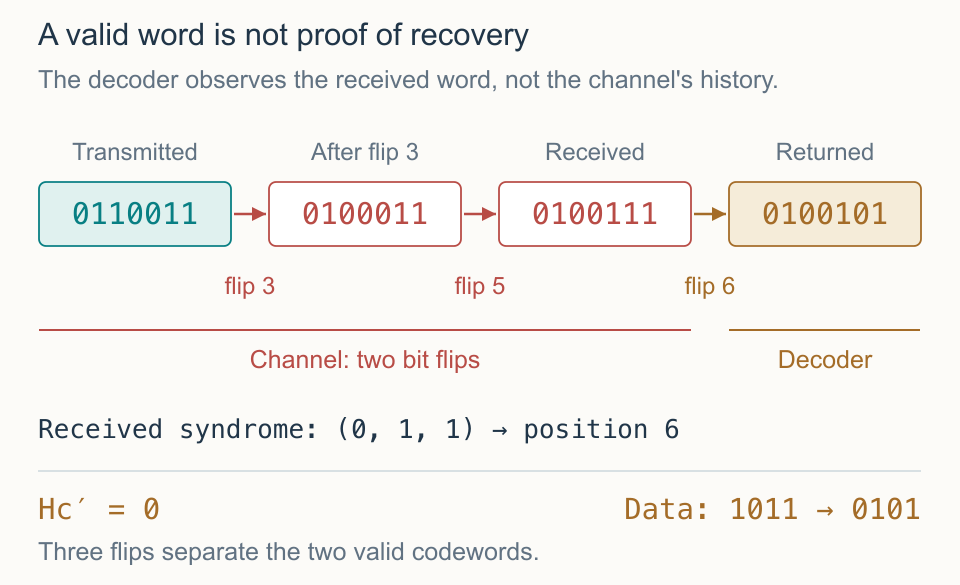

*그림 4. 앞의 두 빨간 flip은 channel에서 생긴 오류다. 받은 값 `0100111`은 check를 통과하지 못한다. 마지막 flip은 decoder가 한 수정이며, 그 뒤의 후보 `0100101`은 모든 check를 통과한다. 하지만 후보에서 읽은 message는 원본과 다르다.*


이렇게 잘못 고치는 경우를 **miscorrection**이라고 한다. Syndrome 계산 자체는 맞다. 어떤 check가 실패했는지도 정확히 알려준다. 문제는 이 결과를 한 bit 오류라고 해석한 데 있다. 여러 bit가 뒤집혀도 같은 syndrome이 나올 수 있기 때문이다.

Syndrome이 0이어도 알 수 있는 것은 $r$이 codeword라는 사실뿐이다. `0110011`의 3, 5, 6번 bit를 뒤집으면 `0100101`이 되고, 모든 check를 통과한다. 따라서 이 결과는 “오류를 찾지 못했다”는 뜻이지 반드시 “오류가 없다”는 뜻은 아니다. 오류가 최대 몇 개 생겼는지 모르는 상태에서는 둘을 같은 말로 쓸 수 없다.


In [4]:
def flip_positions(word, *positions):
    result = list(word)
    for j in positions:
        if not 1 <= j <= len(result):
            raise ValueError("Position outside the word")
        result[j - 1] ^= 1
    return tuple(result)

sent = encode_hamming("1011")
two_errors = flip_positions(sent, 3, 5)
assert two_errors == tuple(map(int, "0100111"))
assert syndrome(two_errors) == (0, 1, 1)  # 0 + 2 + 4 = 6
assert decode_assuming_one_error(two_errors) == (0, 1, 0, 1)
assert syndrome(flip_positions(sent, 3, 5, 6)) == (0, 0, 0)


## 11. Parity bit를 하나 더 붙여 한 bit 오류와 두 bit 오류 구분하기


이제 목표를 **한 bit 오류는 고치되, 정확히 두 bit가 뒤집혔을 때는 잘못 수정하는 대신 복구 실패를 알린다**로 바꿔 보자. 두 bit 오류까지 고치겠다는 목표는 아니다. 그러려면 4절에서 구한 조건에 따라 minimum distance가 적어도 5여야 한다. 한 bit가 뒤집히면 전체 parity가 바뀌지만, 두 bit가 뒤집히면 그대로라는 차이를 이용하면 새 목표를 달성할 수 있다.

일곱 bit Hamming codeword 뒤에 전체 parity bit $q$를 붙이자.

$$
\begin{gathered}
q=c_1+c_2+\cdots+c_7,\\
\widetilde c=(c_1,\ldots,c_7,q)^T.
\end{gathered}
\tag{28}
$$

예를 들어 `0110011`은 weight가 4이므로 $q=0$을 붙여 `01100110`을 보낸다. 반면 message `1000`의 codeword `1110000`은 weight가 3이므로 $q=1$을 붙여 `11100001`을 보낸다. 이처럼 $q$는 codeword마다 달라지지만, **완성한 여덟 bit의 XOR은 언제나 0**이다. 수신자는 원래 message를 몰라도 오류가 없다면 전체 XOR이 0이어야 한다는 것을 안다.

새 minimum distance는 4다. 원래 codeword 두 개 사이의 거리를 $d\ge3$이라고 하자. $d$가 짝수이면 덧붙인 parity bit가 같으므로 거리는 그대로 $d\ge4$다. $d$가 홀수이면 덧붙인 parity bit도 달라져 거리가 $d+1\ge4$가 된다. 원래 거리가 3인 codeword 쌍도 있으므로, 확장한 뒤 거리가 정확히 4인 쌍도 있다. 이렇게 만든 code가 **extended Hamming $[8,4,4]$ code**다. Hamming의 원 논문에서도 single-error correction과 double-error detection을 결합하는 방법을 다룬다. [Hamming, 1950](https://doi.org/10.1002/j.1538-7305.1950.tb00463.x)

수신자는 앞의 일곱 bit로 syndrome $s$를 계산하고, **받은 여덟 bit 전체**를 XOR해 $z$도 구한다. 다음 규칙은 **오류가 0개·1개·2개인 모든 경우**에 새 목표대로 동작한다. 표에서 해석한 오류 개수는 이 범위 안에서 보장된다. Check 결과만으로 세 bit 이상의 오류가 불가능하다고 알아낸 것은 아니다.

| $s$ | $z$ | 의미와 처리 |
| :---: | :---: | :--- |
| $s=0$ | 0 | 오류가 없다. 그대로 둔다. |
| $s\ne0$ | 1 | 1–7번 중 bit 하나가 뒤집혔다. $s$가 가리키는 위치를 고친다. |
| $s=0$ | 1 | 8번 bit만 뒤집혔다. 전체 parity bit를 고친다. |
| $s\ne0$ | 0 | 두 bit가 뒤집혔다. 복구 불가를 알리고, message는 반환하지 않는다. |


두 bit 오류에서는 왜 마지막 행의 결과가 나올까? 1–7번 중 서로 다른 두 bit가 뒤집히면 syndrome은 $H$의 서로 다른 두 열의 합이므로 0이 아니다. 두 오류 중 하나가 8번에 있다면, 나머지 bit 하나가 뒤집힌 결과만 syndrome에 반영되므로 역시 0이 아니다. 어느 경우든 두 bit가 뒤집혔으므로 전체 parity는 짝수인 채로 유지되고, $s$는 0이 아니다.



**같은 수신값을 만드는 네 개의 원본**


받은 값 `01001110`에서 거리가 2 이하인 extended codeword를 모두 찾으면 정확히 네 개다. 다음 네 전송은 모두 같은 수신값을 만든다.

| 보낸 codeword | 뒤집힌 위치 | 원래 message |
| :--- | :--- | :--- |
| `01001011` | 6, 8 | `0101` |
| `11001100` | 1, 7 | `0110` |
| `00011110` | 2, 4 | `0111` |
| `01100110` | 3, 5 | `1011` |


네 codeword 모두 extended encoder로 만들 수 있고, 네 경우 모두 정확히 두 bit가 뒤집혔다. 받은 값이 같으므로 check 결과도 $s=(0,1,1)$, $z=0$으로 같다. 설령 외부에서 “오류가 최대 두 개”라는 조건을 알려 주더라도 가능한 원본 message가 네 개 남는다. 따라서 SECDED 규칙은 어느 bit를 되돌릴지 추측하는 대신 오류를 알린다.



이 처리 방식을 **SECDED**, 즉 single-error correction, double-error detection이라고 한다. 한 bit 오류는 고치고, 두 bit 오류는 발견했다고 알리는 방식이다. 두 bit까지 고치는 방식은 아니다. Minimum distance가 4인 code를 **codeword인지 검사하는 용도로만 쓰면** 한 개부터 세 개까지의 모든 bit 오류를 찾을 수 있다. 하지만 오류 수정까지 하는 SECDED decoder는 모든 three-bit 오류를 single-bit 오류와 구별할 수 없다. 한 bit가 뒤집혀도, 세 bit가 뒤집혀도 전체 parity가 바뀌어 $z=1$이 되기 때문이다. **Codeword인지 검사해서 찾을 수 있는 오류의 범위와, 오류 수정까지 하는 decoder의 보장 범위는 구분해야 한다.**

예를 들어 3, 5, 6번 bit를 뒤집으면 앞의 일곱 bit로 구한 syndrome은 0이지만, 전체 parity를 검사한 결과는 $z=1$이다. 8번 bit 하나만 뒤집힌 경우와 check 결과가 같다. 따라서 SECDED decoder는 전체 parity bit를 수정한다. 하지만 앞의 일곱 bit에서 읽은 message는 여전히 원본과 다르다.

[Hamming 실습](https://pilkwangkim.github.io/posts/Error-Correcting-Codes-From-Scratch-KR/#lab-ecc-hamming)에서 **Extended (8,4)**를 선택해 보자. 5번만 뒤집은 경우, 8번만 뒤집은 경우, 3번과 5번을 함께 뒤집은 경우를 비교하자. 다음에는 세 bit를 뒤집어 보자. 오류가 세 개 이상이면 위 표대로 판단했을 때 틀릴 수 있음을 확인하자.



**간단한 SECDED 구현**


In [5]:
def encode_extended(message):
    c = encode_hamming(message)
    return c + (sum(c) % 2,)

def decode_extended(received):
    """Classification is guaranteed for at most two flips in eight bits."""
    r = list(as_bits(received, 8))
    s1, s2, s4 = syndrome(r[:7])
    j = s1 + 2 * s2 + 4 * s4
    z = sum(r) % 2
    if j and not z:
        return None, "detected double error"  # Refuse to guess.
    if z:
        r[(j - 1) if j else 7] ^= 1
        status = "corrected code bit" if j else "corrected overall parity"
    else:
        status = "no error detected"
    return tuple(r[i] for i in (2, 4, 5, 6)), status

extended = encode_extended("1011")
assert extended == tuple(map(int, "01100110"))
assert decode_extended(flip_positions(extended, 5))[0] == (1, 0, 1, 1)
assert decode_extended(flip_positions(extended, 8))[1] == "corrected overall parity"
assert decode_extended(flip_positions(extended, 3, 5))[0] is None


## 12. 정해 둔 오류 범위에서 모든 경우 테스트하기


네 bit로 만들 수 있는 message는 열여섯 개뿐이다. 각 message에 대해 오류가 없는 경우와, 일곱 위치 각각에서 bit 하나가 뒤집힌 경우를 모두 테스트하자. 총 $16(1+7)=128$가지다. 일부를 무작위로 골라 확인하는 대신, 정해 둔 입력과 오류 조건에 해당하는 모든 경우를 확인할 수 있다.


In [6]:
from itertools import product, combinations

messages = list(product((0, 1), repeat=4))
codebook = [encode_hamming(m) for m in messages]
assert len(set(codebook)) == 16
assert all(syndrome(c) == (0, 0, 0) for c in codebook)

def distance(a, b):
    return sum(x != y for x, y in zip(a, b))

assert min(distance(a, b) for a, b in combinations(codebook, 2)) == 3

tested = 0
for m in messages:
    c = encode_hamming(m)
    for positions in [()] + [(j,) for j in range(1, 8)]:
        r = flip_positions(c, *positions)
        assert decode_assuming_one_error(r) == m
        tested += 1
assert tested == 128
print("Verified:", tested, "clean or single-flip cases")


Verified: 128 clean or single-flip cases


SECDED에서는 여덟 위치 중 0개, 1개, 2개를 뒤집는 모든 경우를 검사하면 된다. $16(1+8+\binom82)=592$가지다. [다운로드용 구현과 실행 예제](https://pilkwangkim.github.io/assets/code/error-correcting-codes.py)도 같은 bit 배치와 matrix를 사용한다. 이 구현은 “한 bit 오류라고 가정하고 수정을 시도했다”는 것과 “원래 message를 반드시 복구한다”는 것을 구분한다. 저장소의 테스트에는 Hamming code의 two-bit 오류 336가지도 포함되어 있다. 표준 single-error decoder는 이 모든 경우를 잘못 수정한다.

이 테스트로 정해 둔 모든 입력과 error pattern에서 구현이 맞는지 확인할 수 있다. 다만 왜 이 code가 오류를 고치는지, 더 긴 code에서도 무엇이 성립하는지는 distance와 syndrome에 대한 증명으로 설명해야 한다. 테스트가 그 증명을 대신하지는 않는다.

## 13. 연습문제: 수신자는 무엇을 알 수 있을까?

### A. 두 번 반복하는 것만으로는 왜 부족할까?

0을 `00`으로, 1을 `11`로 encoding한다. 이 문제에서는 전송 중 최대 한 bit만 바뀌었다는 조건을 주며, 받은 값은 `01`이다. 원래 보낸 codeword로 가능한 값을 모두 적어 보자. 0과 1의 개수가 같을 때 항상 한쪽을 고르는 규칙을 정하면, 어느 message를 보냈더라도 항상 맞힐 수 있을까?



**풀이**


`00`과 `11` 모두 가능하다. `00`의 2번 bit가 뒤집혔을 수도, `11`의 1번 bit가 뒤집혔을 수도 있다. 항상 0을 고르면 두 번째 경우에 틀리고, 항상 1을 고르면 첫 번째 경우에 틀린다. Minimum distance가 2라서 한 bit 오류를 복구하는 데 필요한 3보다 작다. 같은 수일 때 어느 쪽을 고를지 정해도, 원래 무엇을 보냈는지 알 수 있는 정보가 늘어나지는 않는다.



### B. Syndrome의 순서를 지켜 오류를 찾아보자

받은 값이 `0010011`이다. 최대 한 bit가 뒤집혔다고 가정하고, $(s_1,s_2,s_4)$를 계산해 오류 위치와 원래 message의 네 bit를 구해 보자. 앞의 예제와 눈으로 비교하기보다 그림 2의 parity check를 사용하자.



**풀이**


Syndrome은 $(0,1,0)$이므로 $j=2$다. 2번 bit를 뒤집으면 `0110011`이 되고, message bit가 있는 3, 5, 6, 7번 위치를 읽으면 `1011`을 얻는다. Parity bit에 생긴 오류도 같은 규칙으로 고칠 수 있다.



### C. 정상적인 codeword가 나왔으면 복구도 성공한 걸까?

그림 4에서는 decoder가 `0100111`의 bit 하나를 뒤집어 `0100101`을 만들었다. 결과는 모든 check를 통과한다. 원래 message를 복구했다고 판단하려면 어떤 조건이 더 필요할까?



**풀이**


앞에서 증명한 복구 조건은 channel에서 뒤집힌 bit가 최대 하나일 때 성립한다. 후보가 check를 통과해도 알 수 있는 것은 codeword라는 사실뿐이다. 그림에서는 두 bit가 뒤집혔으므로 복구 조건을 적용할 수 없고, 실제 결과도 원본과 다르다. 같은 세 parity check로는 “오류가 최대 하나”라는 가정까지 확인할 수 없다.



### D. SECDED는 왜 수정을 거부할까?

Extended mode에서 `01100110`을 보냈는데 3번과 5번 bit가 뒤집혔다. $s$와 $z$는 각각 얼마인가? Hamming mode에서처럼 syndrome이 가리키는 위치를 수정하면 왜 안 될까?



**풀이**


$s=(0,1,1)$이고 $z=0$이다. 한 bit 오류라고 해석하면 syndrome은 6번 위치를 가리킨다. 하지만 전체 parity가 짝수이므로 정확히 한 bit가 뒤집힌 경우는 아니다. 오류가 최대 두 개라는 가정 아래에서는 두 bit가 뒤집힌 경우만 남는다. SECDED는 이를 발견하면 수정을 시도하지 않고 message도 반환하지 않는다.



아래 퀴즈에서는 **정확히 한 bit가 뒤집혔다**고 가정한다. 오류 위치를 찾고 원래 message를 복구해 보자. 막히면 정답을 확인하기 전에 parity check 힌트를 열어 보자. 오류가 하나라는 것은 문제에서 주어진 조건이다. Syndrome이 0이 아니라는 이유만으로 오류 개수가 하나라고 판단한 것은 아니다.


[Interactive example 열기](https://pilkwangkim.github.io/posts/Error-Correcting-Codes-From-Scratch-KR/#lab-ecc-quiz)


## 14. Coding exercise: 열여섯 codeword를 나열하지 않고 복구하기

`decode_single(received)`를 구현하자. 입력은 $(p_1,p_2,d_1,p_4,d_2,d_3,d_4)$ 순서의 일곱 bit tuple이다. 앞의 encoder가 만든 codeword에서 **최대 한 bit가 뒤집혔다.** 원래 message의 네 bit를 tuple로 반환하면 된다. 오류가 없는 블록도 처리해야 한다.

세 parity check를 직접 계산해도 되고, 위치 번호를 XOR하는 방법을 써도 된다. 열여섯 codeword를 전부 나열해 비교하지는 말자. 이 code의 길이는 일곱으로 고정되어 있다. 받은 bit를 한 번씩 확인하고 일정한 크기의 추가 공간만 사용하면 풀 수 있다.


In [7]:
def decode_single(received):
    # Exercise starter. Preserve the original input.
    # 1. Find the syndrome's position label.
    # 2. Correct one bit if the label is nonzero.
    # 3. Extract positions 3, 5, 6, and 7.
    raise NotImplementedError("Complete the decoder")


함수를 완성했으면 아래 `check_decoder`에 전달해 보자. Parity bit에 생긴 오류까지 포함해 128가지 경우를 모두 검사한다.


In [8]:
def check_decoder(candidate):
    total = 0
    for m in product((0, 1), repeat=4):
        c = encode_hamming(m)
        for positions in [()] + [(j,) for j in range(1, 8)]:
            r = flip_positions(c, *positions)
            before = tuple(r)
            assert candidate(r) == m, (m, positions, r)
            assert r == before, "Do not mutate the input"
            total += 1
    return total

# After filling in the starter:
# assert check_decoder(decode_single) == 128


**힌트: 값이 1인 bit의 위치 번호를 XOR해 보자**


Syndrome은 받은 bit 중 값이 1인 위치에 해당하는 $H$의 열들을 더한 것이다. $j$번째 열에는 위치 번호 $j$를 세 bit로 표현한 값이 들어 있다. 따라서 이 열들을 $\mathbb F_2$에서 더하는 것은 위치 번호를 정수로 놓고 **bitwise XOR**하는 것과 같다. Python의 `label ^= j`는 binary 표현의 세 자리를 한꺼번에 XOR한다. 위치 번호를 보통 덧셈으로 더하는 것이 아니다.





**예시 풀이와 증명**


In [9]:
def decode_single_reference(received):
    r = list(as_bits(received, 7))
    label = 0
    for j, bit in enumerate(r, start=1):
        if bit:
            label ^= j       # XOR labels, not bits or arithmetic positions.
    if label:
        r[label - 1] ^= 1
    return tuple(r[i] for i in (2, 4, 5, 6))

assert check_decoder(decode_single_reference) == 128


정상적인 codeword는 $Hc=0$이므로, 값이 1인 bit의 위치 번호를 모두 XOR하면 0이다. $j$번 bit가 뒤집히면 이 결과에 $j$가 한 번 더 XOR된다. Bit가 0에서 1이 되든 1에서 0이 되든 마찬가지다. 같은 번호를 두 번 XOR하면 0이 되기 때문이다. 따라서 XOR 계산 결과는 오류가 없으면 0, 한 bit가 뒤집혔으면 그 위치 번호다. 해당 bit를 고친 뒤 message bit를 읽으면 원래 message를 복구할 수 있다.

예시 풀이의 함수 이름은 연습용 함수와 다르다. 따라서 실행해도 작성 중인 풀이를 덮어쓰지 않는다.



## 15. 더 큰 시스템에서는 무엇이 달라질까?

Code를 설계할 때는 어떤 오류를 고쳐야 하는지, bit를 얼마나 더 보낼 수 있는지, 원본을 판단할 정보가 부족하면 decoder가 어떻게 처리할지 정해야 한다. 앞의 작은 code에서도 이 세 가지 선택을 확인할 수 있다.

**더 긴 Hamming code.** 서로 다르고 zero vector가 아닌 모든 $a$ bit column을 모아 parity-check matrix를 만들 수 있다. 열의 개수는 $n=2^a-1$, rank는 $a$이며, $a\ge2$에서 code의 parameter는 $[2^a-1,\,2^a-1-a,\,3]$이다. Single-bit 오류를 고치는 원리는 그대로다. 블록이 길어지면 rate는 1에 가까워지지만, 반드시 복구할 수 있는 오류는 여전히 블록당 하나다. Rate가 높아진다고 더 많은 오류를 고칠 수 있는 것은 아니다.

**Burst와 interleaving.** Burst가 생기면 한 codeword 안의 여러 bit가 뒤집힐 수 있다. Interleaver는 전송 전에 여러 codeword의 bit를 섞어 배치한다. 받은 뒤에는 섞었던 순서를 되돌린다. 이렇게 하면 전송 중 한곳에 몰린 오류가 여러 블록으로 나뉠 수 있다. Interleaver 자체가 오류를 고치는 것은 아니며, 얼마나 효과가 있는지는 burst의 형태와 함께 사용하는 code에 달려 있다. [MIT 6.02](https://web.mit.edu/6.02/www/f2011/handouts/6.pdf)

**Reed–Solomon code.** Bit 하나를 symbol로 사용하는 대신, 더 큰 finite field의 원소를 symbol로 쓴다. Finite field는 원소 수가 유한한 field다. 예를 들어 symbol 하나가 여덟 bit를 묶은 한 byte를 나타낼 수 있다. QR code 개발사 DENSO WAVE에 따르면 QR code도 Reed–Solomon redundancy를 사용한다. 다만 문서의 복구 수준은 codeword 기준이다. 인쇄된 QR code에서 같은 비율의 면적을 아무 곳이나 훼손해도 복구된다는 뜻은 아니다. [DENSO WAVE](https://www.qrcode.com/en/about/error_correction.html)



**Polynomial로 symbol을 보호하는 원리**


Polynomial의 **degree**는 계수가 0이 아닌 항 중 가장 큰 지수다. 예를 들어 $a_0+a_1x+a_2x^2$에서 $a_2\ne0$이면 degree는 2다. Field에서 degree가 $k$보다 작은 polynomial은 서로 다른 $k$개 지점의 값으로 정해진다. 계수 $k$개를 message로 보고, 서로 다른 field 원소 $n$개를 대입한 값을 전송하자. 여기서 $1\le k\le n$이며, 서로 다른 대입값을 골라야 하므로 $n$은 선택한 field의 원소 수보다 클 수 없다. 서로 다른 두 polynomial을 빼면 0이 아니고 degree가 최대 $k-1$인 polynomial이 된다. 따라서 그 값이 0이 되는 서로 다른 **root**는 최대 $k-1$개다. 두 polynomial에 같은 값을 대입했을 때 결과가 같을 수 있는 위치도 최대 $k-1$개이므로, 전송하는 vector는 적어도 $n-k+1$개 위치에서 다르다.

이 code의 minimum distance는 정확히 $n-k+1$이다. 선택한 대입값 중 $k-1$개를 root로 갖는 polynomial과, 값이 항상 0인 polynomial을 비교하면 그 거리를 얻는다. 따라서 위치를 모르는 symbol 오류는 최대 $\lfloor(n-k)/2\rfloor$개, erasure는 최대 $n-k$개까지 복구할 수 있다. Bit 대신 더 큰 symbol을 쓰면 오류 하나로 세는 단위가 달라진다. Minimum distance로 복구 한계를 구하는 원리는 같다.

0이 아닌 polynomial에서는 서로 다른 root의 개수가 degree보다 많을 수 없다. Root $a$가 있으면 그 polynomial을 $(x-a)$와 다른 polynomial의 곱으로 쓸 수 있기 때문이다. $(x-a)$를 하나씩 분리할 때마다 남은 polynomial의 degree가 1씩 줄어든다. 이 원리로 실제 byte 기반 encoder를 만들려면 finite-field 연산이 필요하다. 일반적인 정수 연산을 modulo 256으로 계산한다고 field가 되는 것은 **아니다.** 예를 들어 정수 $x$에 대해 $2x$는 항상 짝수이므로 modulo 256으로 계산해도 1이 될 수 없다. 따라서 0이 아닌 원소 2의 inverse가 없고, field에서처럼 2로 나눌 수 없다. 여러 지점에서 구한 polynomial 값을 전송하는 방법은 Reed와 Solomon의 원 논문에 제시되어 있다. [Reed and Solomon, 1960](https://sites.math.rutgers.edu/~zeilberg/akherim/ReedS1960.pdf)



**Integrity와 authenticity는 다르다.** Error-correcting code는 정해 둔 error pattern에서 데이터를 보호한다. 하지만 공개된 code 조건만으로는 공격자가 다른 정상적인 codeword로 값을 바꾸는 일을 막을 수 없다. 데이터가 권한 있는 송신자에게서 왔는지, 허가 없이 변경되지는 않았는지 확인하는 **cryptographic authentication**은 별도의 문제다. Parity check를 통과했다는 사실만으로는 이를 확인할 수 없다.

## 16. Redundancy가 오류 복구를 가능하게 하는 이유


처음 정한 목표는 오류가 없거나 한 bit만 바뀐 모든 경우에 message를 복구하는 것이었다. 더 큰 오류가 절대 생기지 않는다고 가정한 것이 아니다. 네 bit를 그대로 보낼 때는 이 범위 안에서도 수신값 `1001`의 원본 후보가 다섯 개였다. Hamming encoding은 열여섯 message를 모두 유지하면서, 이를 가능한 일곱 bit word 128개 중 열여섯 codeword로 바꾼다. 이들 사이의 minimum distance는 3이다. 따라서 **실제로 뒤집힌 bit가 최대 하나라면** 받은 값에서 거리 1 이내의 codeword가 정확히 하나이고, 원래 message를 복구할 수 있다. 이것으로 처음 정한 목표를 달성했다.

Parity check는 이 codeword들이 만족할 조건을 linear equation으로 표현한다. 받은 값에 $H$를 곱하면 원래 codeword에 해당하는 항 $Hc$는 0이 되고, syndrome에는 error vector에 따른 결과 $He$만 남는다.

Hamming decoder가 bit 하나를 고칠 수 있는 것은 원본을 알고 있어서가 아니다. **오류가 없을 때와 각 위치에서 bit 하나가 뒤집혔을 때 syndrome이 모두 다르기 때문**이다. 하지만 두 bit 이상 뒤집힐 수 있다면 서로 다른 전송이 같은 수신값을 만들 수 있다. 이런 경우에는 받은 값과 check 결과만으로 실제 전송을 하나로 정할 수 없다. SECDED가 두 bit 오류를 발견했을 때 message를 추측하지 않고 복구 불가를 알리는 이유도 이 때문이다.

## 참고자료와 실행 코드

1. **R. W. Hamming (1950), “Error Detecting and Error Correcting Codes.”** *Bell System Technical Journal* 29(2), 147–160. [DOI](https://doi.org/10.1002/j.1538-7305.1950.tb00463.x) · [논문 스캔](https://zoo.cs.yale.edu/classes/cs323/doc/Hamming.pdf). Distance, redundancy, single-error correction 구성을 제시한 원 논문.
2. **MIT 6.02, Chapter 6, “Coping with Bit Errors using Error Correction Codes.”** [강의 자료](https://web.mit.edu/6.02/www/f2011/handouts/6.pdf). Repetition, distance, parity check, Hamming construction, burst error를 다룬다.
3. **MIT MAS 160/510, “Additional Notes: Error-Correcting Codes.”** [Matrix를 이용한 유도](https://courses.media.mit.edu/2007fall/mas160/error.pdf). Linear encoding, parity-check matrix, syndrome decoding을 설명한다. Row vector를 쓰는지 column vector를 쓰는지는 본문과 다를 수 있다.
4. **IBM Quantum Learning, “Repetition codes”의 classical 부분.** [강의](https://quantum.cloud.ibm.com/learning/en/courses/foundations-of-quantum-error-correction/correcting-quantum-errors/repetition-codes). 독립적인 bit flip에서 majority vote로 decoding하는 방법과 오류 확률을 설명한다. Quantum 부분에서는 그 밖의 오류 유형도 다룬다.
5. **University of Michigan EECS 373, “Error detecting and correcting codes.”** [강의 자료](https://www.eecs.umich.edu/courses/eecs373.w05/lecture/errorcode.html). Parity와 오류 검출·복구의 차이를 설명한다.
6. **DENSO WAVE, “Error Correction Feature.”** [QR code 문서](https://www.qrcode.com/en/about/error_correction.html). Reed–Solomon의 사용과 복원 수준의 의미를 설명한다.
7. **I. S. Reed and G. Solomon (1960), “Polynomial Codes Over Certain Finite Fields.”** *Journal of the Society for Industrial and Applied Mathematics* 8(2), 300–304. [DOI](https://doi.org/10.1137/0108018) · [논문 스캔](https://sites.math.rutgers.edu/~zeilberg/akherim/ReedS1960.pdf). Polynomial 값을 이용한 encoding을 제시한 원 논문.
8. **본문과 함께 사용하는 구현.** [Python standard library만 사용한 구현](https://pilkwangkim.github.io/assets/code/error-correcting-codes.py) · [실행 결과가 포함된 notebook](https://pilkwangkim.github.io/assets/notebooks/error-correcting-codes-ko.ipynb) · [소스 저장소](https://github.com/pilkwangkim/pilkwangkim.github.io). 저장소의 `tools/test_error_correcting_codes.py`가 matrix, distance, decoder의 복구 조건과 실패 사례를 검사한다.
